# Step 4: Customer Segmentation (RFM & K-Means)

**E-Commerce 360° Business Intelligence Platform**

Algorithmic segmentation identifying Champions, High-Value, At-Risk, and Churned cohorts.


### 1. Conceptual Framework: RFM Analysis
Segment customers across three dimensions:
- **Recency ($R$):** Days since most recent purchase.
- **Frequency ($F$):** Total delivered order count.
- **Monetary ($M$):** Total customer lifetime spend (BRL).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

PROCESSED_DIR = r'data/processed'
df = pd.read_csv(f'{PROCESSED_DIR}/order_summary_bi.csv')
df = df[df['order_status'] == 'delivered'].copy()
df['purchase_date'] = pd.to_datetime(df['purchase_date'])

ref_date = df['purchase_date'].max() + pd.Timedelta(days=1)
rfm = df.groupby('customer_unique_id').agg({
    'purchase_date': lambda d: (ref_date - d.max()).days,
    'order_id': 'nunique',
    'total_item_revenue': 'sum'
}).reset_index()

rfm.columns = ['customer_unique_id', 'Recency', 'Frequency', 'Monetary']
rfm.describe().round(2)

,Recency,Frequency,Monetary
count,93358.00,93358.00,93358.00
mean,238.48,1.03,141.62
std,152.60,0.21,215.69
min,1.00,1.00,0.85
25%,115.00,1.00,47.65
50%,219.00,1.00,89.73
75%,347.00,1.00,154.74
max,714.00,15.00,13440.00


### 2. Log Transformation & Standard Scaling
Apply $\log(x+1)$ transformation to handle severe right skewness, followed by z-score standardization.

In [2]:
rfm_log = pd.DataFrame({
    'Recency': np.log1p(rfm['Recency']),
    'Frequency': np.log1p(rfm['Frequency']),
    'Monetary': np.log1p(rfm['Monetary'])
})

scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_log)
print('Log-transformed and scaled feature matrix shape:', X_scaled.shape)

Log-transformed and scaled feature matrix shape: (93358, 3)


### 3. K-Means Clustering ($k=4$) & Silhouette Evaluation
Fit K-Means clustering algorithm and assess separation quality.

In [3]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(X_scaled)

sample_idx = np.random.RandomState(42).choice(len(X_scaled), size=5000, replace=False)
sil_score = silhouette_score(X_scaled[sample_idx], rfm['Cluster'].iloc[sample_idx])
print(f'Silhouette Score (k=4): {sil_score:.4f}')

cluster_profile = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'customer_unique_id': 'count'
}).rename(columns={'customer_unique_id': 'Customer Count'})
cluster_profile.round(2)

Silhouette Score (k=4): 0.3926


,Recency,Frequency,Monetary,Customer Count
Cluster,,,,
0,278.98,1.00,237.26,37665
1,285.20,1.00,45.10,36601
2,220.81,2.11,260.05,2801
3,42.93,1.00,116.99,16291


### 4. Segment Distribution Visualization
Visualize customer clusters across Recency and Monetary dimensions.

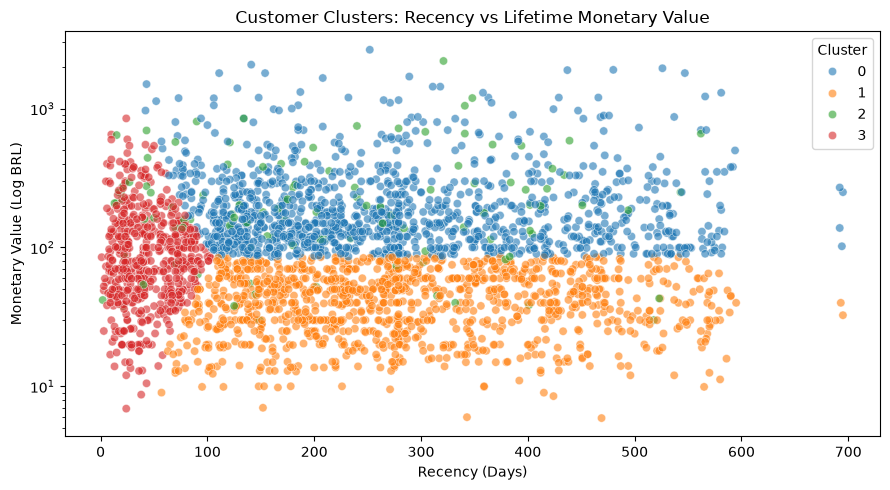

In [4]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=rfm.sample(3000, random_state=42), x='Recency', y='Monetary', hue='Cluster', palette='tab10', alpha=0.6)
plt.yscale('log')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary Value (Log BRL)')
plt.title('Customer Clusters: Recency vs Lifetime Monetary Value')
plt.tight_layout()
plt.show()